# Contraste geográfico y temporal con el registro oficial MINAM
Se consulta la capa oficial «Registro histórico de incendios 2000–2025» del servicio MINAM.
El portal de datos abiertos indicado por el equipo respondió 403; no se ha demostrado que su
recurso descargable sea idéntico a esta capa. Conservamos URL, fecha de consulta y hashes.
Este análisis evalúa asociaciones retrospectivas. No valida aún todos los incendios reales
ni estima la omisión satelital: la independencia de las fuentes sigue sin establecerse.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path(os.environ.get('FIRMS_ARTIFACTS_DIR','outputs')).resolve()
OUT=ROOT/'27_contraste_MINAM'
manifest=json.loads((OUT/'snapshot_manifest.json').read_text())
audit=json.loads((OUT/'registry_comparison.json').read_text())
matches=pd.read_csv(OUT/'spatiotemporal_associations.csv')
corr=pd.read_csv(OUT/'weekly_record_correlations.csv')
display(pd.Series({k:manifest[k] for k in ['source','rows','object_ids_complete','downloaded_at_utc']}))

source                 https://geoservidorperu.minam.gob.pe/arcgis/re...
rows                                                               54493
object_ids_complete                                                 True
downloaded_at_utc                       2026-11-15T03:44:33.397244+00:00
dtype: object

## 1. Procedencia y depuración
Se conservaron todos los identificadores de objeto publicados en el snapshot y se verificó
cada lote contra el manifiesto. Fechas malformadas se reparan solo con componentes explícitos
de año, mes y día cuando existen; conflictos de fecha quedan fuera del contraste principal.
Se eliminan duplicados exactos de referencia, fecha y coordenadas. Un código de emergencia
con varias ubicaciones se cuenta como una referencia: basta una coincidencia en su geometría.
Si no hay código utilizable, la referencia se identifica por fecha y ubicación, no como un
incendio independiente comprobado. Referencias con fechas separadas más de 30 días se excluyen.
Los orígenes INDECI, MINAM y ORORATECH se muestran separados. El rótulo INDECI por sí solo
no prueba independencia de imágenes o alertas satelitales utilizadas durante la elaboración.

In [2]:
display(pd.Series({k:audit[k] for k in ['common_period','eligible_rows_before_exact_dedup',
    'audited_geographic_rows','incident_references','ambiguous_references_over_30_days_excluded',
    'raw_dates_not_strictly_parseable','date_quality']}))
source=json.loads((OUT/'source_composition.json').read_text())
display(pd.DataFrame([f['attributes'] for f in source['features']]))

common_period                                                          2013-01-07 to 2025-12-31
eligible_rows_before_exact_dedup                                                          52103
audited_geographic_rows                                                                   52087
incident_references                                                                       44374
ambiguous_references_over_30_days_excluded                                                    2
raw_dates_not_strictly_parseable                                                             13
date_quality                                  {'conflicting_date_fields_excluded': 33, 'date...
dtype: object

,FTE_INF,ORIGEN,n
0,DMERNT,INDECI,21940
1,INDECI,INDECI,14
2,SINPAD,INDECI,735
3,DMERNT,MINAM,31103
4,DMERNT,ORORATECH,701


## 2. Criterio de coincidencia fijado antes del contraste
Principal: al menos una detección a 5 km de una ubicación registrada y dentro de ±3 días
de calendario. Sensibilidades: 10 km/±3 días y 25 km/±7 días. La fecha se interpreta como
fecha local de Perú, preservando todos los horarios posibles del día; no se inventa una hora
de ignición. La ubicación MINAM puede representar un área afectada o un lugar de reporte.
Se usan las mismas plataformas seleccionadas por instrumento/semana que en la serie publicada.
Un árbol espacial-temporal busca candidatos y luego se aplica distancia circular en LAEA.
Como controles descriptivos, repetimos el contraste desplazando las fechas −28 y +28 días.
Esos controles no son ubicaciones verificadas sin incendio ni permiten calcular especificidad.

,instrument,origin,radius_km,calendar_day_half_window,date_shift_days,incident_references,with_satellite_record,association_fraction
0,MODIS,INDECI,5.0,3,0,15140,2974,0.1964
1,MODIS,MINAM,5.0,3,0,28913,3534,0.1222
2,MODIS,ORORATECH,5.0,3,0,321,115,0.3583
9,MODIS,INDECI,5.0,3,-28,15140,1026,0.0678
10,MODIS,MINAM,5.0,3,-28,28913,1804,0.0624
11,MODIS,ORORATECH,5.0,3,-28,321,30,0.0935
18,MODIS,INDECI,5.0,3,28,15140,917,0.0606
19,MODIS,MINAM,5.0,3,28,28913,1381,0.0478
20,MODIS,ORORATECH,5.0,3,28,321,73,0.2274
27,VIIRS,INDECI,5.0,3,0,15140,6830,0.4511


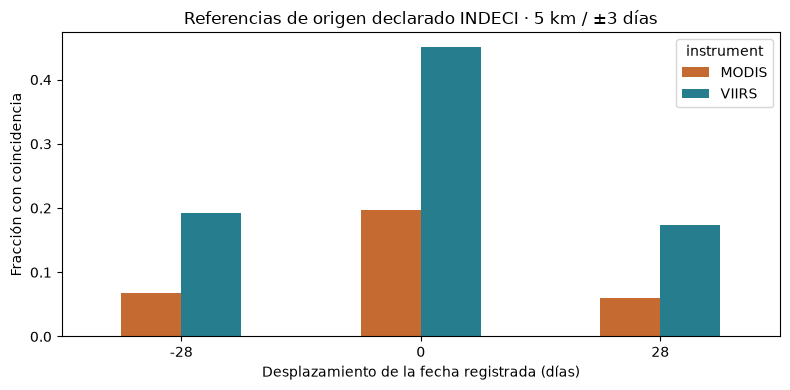

In [3]:
primary=matches.loc[matches.radius_km.eq(5)&matches.calendar_day_half_window.eq(3)]
display(primary.round(4))
plot=primary.loc[primary.origin.eq('INDECI')].pivot(index='date_shift_days',columns='instrument',values='association_fraction')
ax=plot.plot.bar(figsize=(8,4),color=['#c56b31','#257d8e'])
ax.set(xlabel='Desplazamiento de la fecha registrada (días)',ylabel='Fracción con coincidencia',
       title='Referencias de origen declarado INDECI · 5 km / ±3 días')
ax.tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()

## 3. Sensibilidad espacial y temporal
Ampliar radio y ventana aumenta coincidencias incluso por casualidad o persistencia estacional.
Por eso no se elige la ventana que produzca el porcentaje mayor después de ver los resultados.
Una referencia sin coincidencia puede deberse a nubosidad, horario de sobrevuelo, fuego débil,
fecha de reporte, ubicación aproximada o inconsistencias de registro; no es una omisión probada.

In [4]:
sensitivity=matches.loc[matches.date_shift_days.eq(0)]
display(sensitivity.round(4))
assert matches.groupby(['instrument','origin','date_shift_days']).incident_references.nunique().eq(1).all()

,instrument,origin,radius_km,calendar_day_half_window,date_shift_days,incident_references,with_satellite_record,association_fraction
0,MODIS,INDECI,5.0,3,0,15140,2974,0.1964
1,MODIS,MINAM,5.0,3,0,28913,3534,0.1222
2,MODIS,ORORATECH,5.0,3,0,321,115,0.3583
3,MODIS,INDECI,10.0,3,0,15140,4657,0.3076
4,MODIS,MINAM,10.0,3,0,28913,7186,0.2485
5,MODIS,ORORATECH,10.0,3,0,321,167,0.5202
6,MODIS,INDECI,25.0,7,0,15140,9722,0.6421
7,MODIS,MINAM,25.0,7,0,28913,19116,0.6612
8,MODIS,ORORATECH,25.0,7,0,321,286,0.8910
27,VIIRS,INDECI,5.0,3,0,15140,6830,0.4511


## 4. Correlación de registros semanales
Se cuenta la primera fecha de cada referencia declarada INDECI y se compara con los conteos
nacionales de cada instrumento, usando Aqua y Suomi-NPP como plataformas constantes.
Las semanas sin registros MINAM cuentan como cero registros de ese archivo, no cero incendios.
La correlación se informa por período sin modificar los modelos.
Multiplicar una serie por un factor constante positivo conserva Pearson y Spearman. Por tanto,
una correlación alta no demuestra que la escala armonizada sea correcta. Los empates se
preservan redondeando a seis decimales para evitar ruido numérico de las sumas por celda.

In [5]:
display(corr.round(5))
pearson=corr.pivot(index=['instrument','period'],columns='variable',values='pearson')
display((pearson.harmonized_count-pearson.raw_count).rename('cambio_Pearson'))

,instrument,period,variable,weeks,pearson,spearman
0,MODIS,development,raw_count,469,0.44164,0.63981
1,MODIS,development,harmonized_count,469,0.44164,0.63981
2,MODIS,validation,raw_count,103,0.78267,0.87932
3,MODIS,validation,harmonized_count,103,0.78267,0.87932
4,MODIS,final,raw_count,104,0.73736,0.89676
5,MODIS,final,harmonized_count,104,0.73736,0.89676
6,VIIRS,development,raw_count,469,0.53731,0.65991
7,VIIRS,development,harmonized_count,469,0.53731,0.65991
8,VIIRS,validation,raw_count,103,0.78217,0.84250
9,VIIRS,validation,harmonized_count,103,0.78217,0.84250


instrument  period     
MODIS       development    1.110223e-16
            final          0.000000e+00
            validation     0.000000e+00
VIIRS       development    0.000000e+00
            final          0.000000e+00
            validation     0.000000e+00
Name: cambio_Pearson, dtype: float64

## 5. Alcance del resultado
El contraste aporta evidencia de asociación espacio-temporal con un archivo oficial.
Quedan pendientes la auditoría de independencia documental, precisión geográfica, cobertura
de reportes y máscaras de observación históricas. No reemplaza la corrección completa.
Fuente oficial: https://geoservidorperu.minam.gob.pe/arcgis/rest/services/ServicioCFOI/MapServer/1

In [6]:
assert not audit['ground_incident_independence_established']
assert not audit['unmatched_is_proven_omission']
assert not audit['model_changed_from_registry_results']
assert not audit['correlation_validates_global_scale']
print('Contraste retrospectivo documentado. No se declara cobertura corregida ni verdad de ignición.')

Contraste retrospectivo documentado. No se declara cobertura corregida ni verdad de ignición.
